# Neural Networks and Deep Learning — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 7**

This notebook follows the R lecture `lectures/week7/neuralNet.Rmd`, replacing `neuralnet` and `nnet` with scikit-learn's `MLPClassifier`.

| R | scikit-learn `MLPClassifier` |
|---|---|
| `hidden = 3` / `size = 3` | `hidden_layer_sizes=(3,)` |
| `act.fct = "logistic"` | `activation="logistic"` |
| `decay` (weight decay) | `alpha` (L2 penalty) |
| `maxit` | `max_iter` |

For real deep learning (CNNs, RNNs, transformers), use **PyTorch** or **Keras**.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score
from sklearn.datasets import load_iris

## Activation functions

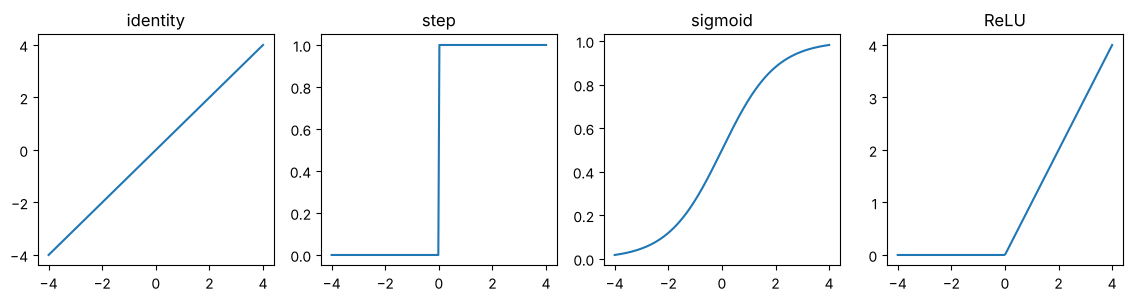

In [2]:
z = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, (name, f) in zip(ax, {"identity": z, "step": (z > 0).astype(float),
                            "sigmoid": 1 / (1 + np.exp(-z)), "ReLU": np.maximum(0, z)}.items()):
    a.plot(z, f); a.set_title(name)
plt.show()

## A toy example: job placement
Scores rescaled to 0–1. `lbfgs` is a good solver for tiny data sets.

In [3]:
df = pd.DataFrame({"TKS": np.array([20, 10, 30, 20, 80, 30]) / 100,
                   "CSS": np.array([90, 20, 40, 50, 50, 80]) / 100,
                   "Placed": [1, 0, 0, 0, 1, 1]})
nn_toy = MLPClassifier(hidden_layer_sizes=(3,), activation="logistic", solver="lbfgs",
                       max_iter=5000, random_state=0).fit(df[["TKS", "CSS"]], df.Placed)
test = pd.DataFrame({"TKS": [0.30, 0.40, 0.85], "CSS": [0.85, 0.50, 0.40]})
test.assign(prob=nn_toy.predict_proba(test)[:, 1].round(3), pred=nn_toy.predict(test))

,TKS,CSS,prob,pred
0,0.30,0.85,1.000,1
1,0.40,0.50,0.095,0
2,0.85,0.40,0.997,1


## Iris: tune hidden-layer size and weight decay, evaluate on a test set

In [4]:
iris = load_iris(as_frame=True)
Xtr, Xte, ytr, yte = train_test_split(iris.data, iris.target, test_size=0.3,
                                      stratify=iris.target, random_state=0)
pipe = make_pipeline(StandardScaler(), MLPClassifier(solver="lbfgs", max_iter=2000, random_state=0))
grid = {"mlpclassifier__hidden_layer_sizes": [(1,), (3,), (5,)],
        "mlpclassifier__alpha": [0, 1e-4, 0.1]}
nn_iris = GridSearchCV(pipe, grid, cv=5).fit(Xtr, ytr)
print(nn_iris.best_params_, " test accuracy:", round(nn_iris.score(Xte, yte), 3))

{'mlpclassifier__alpha': 0, 'mlpclassifier__hidden_layer_sizes': (1,)}  test accuracy: 1.0


## Biomarker development revisited: TB NanoString
Same design as the SVM lecture: 70/30 split, 10-fold CV by AUC. A strong L2 penalty (`alpha`) plays the role of `decay`.

In [5]:
tb = pd.read_csv(DATA + "TBnanostring.csv")
Xtb, ytb = tb.drop(columns="TB_Status"), (tb.TB_Status == "TB").astype(int)
Xtr, Xte, ytr, yte = train_test_split(Xtb, ytb, test_size=0.3, stratify=ytb, random_state=1)
pipe = make_pipeline(StandardScaler(),
                     MLPClassifier(activation="logistic", solver="lbfgs", max_iter=2000, random_state=1))
grid = {"mlpclassifier__hidden_layer_sizes": [(1,), (3,), (5,)],
        "mlpclassifier__alpha": [0.01, 0.1, 1, 10]}
nn_tb = GridSearchCV(pipe, grid, cv=StratifiedKFold(10, shuffle=True, random_state=1),
                     scoring="roc_auc").fit(Xtr, ytr)
p = nn_tb.predict_proba(Xte)[:, 1]
print(nn_tb.best_params_)
print("test AUC:", round(roc_auc_score(yte, p), 3),
      " sensitivity:", round(recall_score(yte, p > 0.5), 3),
      " specificity:", round(recall_score(1 - yte, p <= 0.5), 3))

{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (1,)}
test AUC: 0.938  sensitivity: 0.833  specificity: 1.0


## Convolution and pooling, by hand
A 3×3 filter slides over a 5×5 image (stride 1, no padding), then 2×2 max pooling.

In [6]:
img = np.array([[1,1,1,0,0],[0,1,1,1,0],[0,0,1,1,1],[0,0,1,1,0],[0,1,1,0,0]])
k = np.array([[1,0,1],[0,1,0],[1,0,1]])
conv = np.array([[(img[i:i+3, j:j+3] * k).sum() for j in range(3)] for i in range(3)])
print("convolved feature:\n", conv)
fm = np.array([[1,0,2,3],[4,6,6,8],[3,1,1,0],[1,2,2,4]])
pool = fm.reshape(2, 2, 2, 2).max(axis=(1, 3))
print("max pooled:\n", pool)

convolved feature:
 [[4 3 4]
 [2 4 3]
 [2 3 4]]
max pooled:
 [[6 8]
 [3 4]]


## Scaled dot-product attention, by hand
Three tokens with 4-dimensional queries, keys, and values: each row of the weight matrix sums to 1.

In [7]:
rng = np.random.default_rng(0)
Q, K, V = rng.normal(size=(3, 4)), rng.normal(size=(3, 4)), rng.normal(size=(3, 4))
scores = Q @ K.T / np.sqrt(K.shape[1])
W = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)   # softmax by row
print("attention weights:\n", W.round(3))
print("output:\n", (W @ V).round(3))

attention weights:
 [[0.226 0.475 0.298]
 [0.144 0.598 0.259]
 [0.668 0.235 0.097]]
output:
 [[-0.061  0.287 -0.584 -0.202]
 [-0.185  0.285 -0.654 -0.165]
 [ 0.481  0.167 -0.714 -0.631]]
